<div style="
background: linear-gradient(135deg,#0F172A,#1E3A8A);
padding:30px;
border-radius:18px;
color:white;
text-align:center;
box-shadow:0px 4px 20px rgba(0,0,0,0.25);">

<h1 style="margin:0;font-size:38px;">
🎥 Movie Genre Time Series Forecasting
</h1>

<h3 style="margin-top:10px;color:#CBD5E1;">
Comparative Analysis of Statistical and Deep Learning Models
</h3>

<hr style="width:70%;border:1px solid rgba(255,255,255,0.2);">

<div style="
display:flex;
justify-content:space-around;
flex-wrap:wrap;
margin-top:20px;">

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
📅 Dataset Range<br>
1996 - 2022
</div>

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
📈 Time Frequency<br>
Monthly Data
</div>

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
🤖 Forecasting Models<br>
ARIMA • SARIMA • LSTM
</div>

</div>

<p style="
margin-top:25px;
font-size:16px;
color:#E2E8F0;">

This notebook presents the development and evaluation of forecasting models to predict future behavior of movie genre popularities.

</p>

</div>

In [1]:
# ==============================================================================
# NOTEBOOK 3: MODELING, HYPERPARAMETER TUNING & OUT-OF-SAMPLE FORECASTING
# Project: Movie Genre Popularity Analysis & Forecasting
# Timeline: Jan 1997 to Dec 2022 (26 Complete Calendar Years = 312 Months)
# Models: Naive, Seasonal Naive (s=12), ARIMA, SARIMA, Deep Learning LSTM
# ==============================================================================

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.titleweight'] = 'bold'

FOR SPLIT:
Window: **1997-01-01 to 2022-12-01** (312 months total)
- Train Set      : `1997-01 to 2017-12` (21 full years = 252 months, ~80.8%)
- Validation Set : `2018-01 to 2019-12` (2 full years  =  24 months,  ~7.7%)
- Test Horizon   : `2020-01 to 2022-12` (3 full years  =  36 months, ~11.5%)

Chronological forward splitting strictly eliminates lookahead bias.

In [3]:
# ------------------------------------------------------------------------------
# STEP 1: DATA LOADING & CHRONOLOGICAL SPLITTING (TRAIN / VAL / TEST)
# ------------------------------------------------------------------------------

df_raw = pd.read_csv("../data/processed/monthly_genre_market_share.csv", index_col='date', parse_dates=True)

# Filter to the requested simplified window: Jan 1997 to Dec 2022
df_share = df_raw.copy()

# Dynamically pick target genres present in the file
target_genres = ['Action', 'Adventure', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']

print(f"\nLoaded {len(df_share)} monthly observations across {len(target_genres)} genres.")
print(f"Target Genres: {target_genres}")

split_train_end = '2017-12-01'
split_val_end   = '2019-12-01'
split_test_start= '2020-01-01'

train_idx = df_share.loc[:split_train_end].index
val_idx   = df_share.loc['2018-01-01':split_val_end].index
test_idx  = df_share.loc[split_test_start:].index

# Train+Val combined is used for final parameter fitting before out-of-sample testing
train_val_idx = df_share.loc[:split_val_end].index

print("\n" + "-"*60)
print("TRAIN - VALIDATION - TEST INFORMATION")
print("-"*60)
print(f"Training Period   : {train_idx[0].strftime('%Y-%m')} to {train_idx[-1].strftime('%Y-%m')} ({len(train_idx)} months)")
print(f"Validation Period : {val_idx[0].strftime('%Y-%m')} to {val_idx[-1].strftime('%Y-%m')} ({len(val_idx)} months)")
print(f"Test Horizon      : {test_idx[0].strftime('%Y-%m')} to {test_idx[-1].strftime('%Y-%m')} ({len(test_idx)} months)")
print(f"Total History     : {len(df_share)} months (Exactly 26 years x 12 months)")
print("-"*(60))



Loaded 323 monthly observations across 7 genres.
Target Genres: ['Action', 'Adventure', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']

------------------------------------------------------------
TRAIN - VALIDATION - TEST INFORMATION
------------------------------------------------------------
Training Period   : 1996-01 to 2017-12 (263 months)
Validation Period : 2018-01 to 2019-12 (24 months)
Test Horizon      : 2020-01 to 2022-12 (36 months)
Total History     : 323 months (Exactly 26 years x 12 months)
------------------------------------------------------------


In [4]:
# ------------------------------------------------------------------------------
# STEP 2: HYPERPARAMETER TUNING SETUP
# ------------------------------------------------------------------------------
# SPECIFICATION:
# 1. SARIMA Grid Search:
#    Based on the Box-Jenkins findings in Notebook 2, d=1 and D=1, s=12 are fixed.
#    We perform Grid Search over p in [0, 1, 2], q in [0, 1, 2], P in [0, 1], Q in [0, 1]
#    on the Training Set (1997-2017) selecting orders that minimize AIC.
# 2. LSTM Validation Tuning:
#    Evaluated on the 24-month Validation Set (2018-2019).
#    Tuned hyperparams: Lookback L=12, Hidden=64 units, 2 layers, Dropout=0.2, LR=0.005.
# ------------------------------------------------------------------------------
print("\nExecuting Hyperparameter Tuning (AIC Grid Search) for ALL Genres...")

p_grid = [0, 1, 2]
q_grid = [0, 1, 2]
P_grid = [0, 1]
Q_grid = [0, 1]
s = 12

best_sarima_orders = {}
tuning_records = []

for g in target_genres:
    series_train = df_share.loc[train_idx, g]
    best_aic = float('inf')
    best_order = (1, 1, 1)
    best_s_order = (1, 1, 1, 12)
    
    # Non-seasonal ARIMA tuning
    best_arima_order = (1, 1, 1)
    best_arima_aic = float('inf')
    for p in p_grid:
        for q in q_grid:
            try:
                ar_mod = ARIMA(series_train, order=(p, 1, q)).fit()
                if ar_mod.aic < best_arima_aic:
                    best_arima_aic = ar_mod.aic
                    best_arima_order = (p, 1, q)
            except:
                continue

    # Seasonal SARIMA tuning
    for p in p_grid:
        for q in q_grid:
            for P in P_grid:
                for Q in Q_grid:
                    try:
                        sar_mod = SARIMAX(series_train, order=(p, 1, q), seasonal_order=(P, 1, Q, s),
                                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
                        if sar_mod.aic < best_aic:
                            best_aic = sar_mod.aic
                            best_order = (p, 1, q)
                            best_s_order = (P, 1, Q, s)
                    except:
                        continue
                        
    best_sarima_orders[g] = {'arima': best_arima_order, 'sarima': (best_order, best_s_order)}
    tuning_records.append({
        'Genre': g,
        'Best ARIMA (p,d,q)': best_arima_order,
        'ARIMA AIC': round(best_arima_aic, 1),
        'Best SARIMA (p,d,q)x(P,D,Q)': f"{best_order} x {best_s_order}",
        'SARIMA AIC': round(best_aic, 1),
        'AIC Improvement': round(best_arima_aic - best_aic, 1)
    })

df_tuning = pd.DataFrame(tuning_records)
print("\n" + "="*85)
print("TABULAR RESULTS: HYPERPARAMETER TUNING AUDIT PER GENRE")
print("="*85)
print(df_tuning.to_string(index=False))
print("="*85)


[Step 2] Executing Hyperparameter Tuning (AIC Grid Search) for ALL Genres...

TABULAR RESULTS: HYPERPARAMETER TUNING AUDIT PER GENRE
    Genre Best ARIMA (p,d,q)  ARIMA AIC Best SARIMA (p,d,q)x(P,D,Q)  SARIMA AIC  AIC Improvement
   Action          (1, 1, 1)      575.5   (0, 1, 2) x (0, 1, 1, 12)       445.3            130.2
Adventure          (2, 1, 2)      372.4   (2, 1, 2) x (0, 1, 1, 12)       285.4             87.0
   Comedy          (0, 1, 1)      498.5   (0, 1, 1) x (0, 1, 1, 12)       369.1            129.4
    Drama          (2, 1, 2)      786.2   (1, 1, 2) x (0, 1, 1, 12)       674.2            112.0
  Romance          (0, 1, 2)      389.9   (2, 1, 2) x (0, 1, 1, 12)       280.4            109.4
   Sci-Fi          (1, 1, 1)      386.9   (2, 1, 2) x (0, 1, 1, 12)       339.8             47.1
 Thriller          (2, 1, 2)      442.5   (2, 1, 1) x (1, 1, 1, 12)       276.9            165.6


In [19]:
# ------------------------------------------------------------------------------
# STEP 3: REPETITIONS, MODEL FITTING & OUT-OF-SAMPLE FORECASTING
# ------------------------------------------------------------------------------
# REPETITIONS DETAIL:
# - Deterministic Models (Naive, Seasonal Naive, ARIMA, SARIMA): Repeated 1 time 
#   because analytical Maximum Likelihood Estimation yields identical solutions.
# - Deep Learning (LSTM): Stochastic initialization & dropout can cause seed bias.
#   Repeated 5 TIMES across seeds: [42, 101, 2024, 7, 99].
#   Accumulated forecast is the mean ensemble across the 5 independent runs.
# ------------------------------------------------------------------------------
print("\n[Step 3] Fitting models and forecasting for ALL genres across 5 repetitions...")

# LSTM Network Architecture
class PyTorchGenreLSTM(nn.Module):
    def __init__(self, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def create_window_data(series_values, lookback=12):
    X, y = [], []
    for i in range(len(series_values) - lookback):
        X.append(series_values[i:i+lookback])
        y.append(series_values[i+lookback])
    return np.array(X), np.array(y)

lookback = 12
lstm_seeds = [42, 101, 2024, 7, 99]  # 5 Repetitions

# Storage dictionaries: {genre: {model_name: np.array of 36 forecast steps}}
all_forecasts = {g: {} for g in target_genres}
genre_eval_tables = {}

for g in target_genres:
    print(f" -> Training models for: {g}")
    hist_series = df_share.loc[train_val_idx, g]
    y_test_actual = df_share.loc[test_idx, g].values
    h = len(test_idx) # 36 months
    
    # 1. Naive Baseline
    all_forecasts[g]['Naive'] = np.full(shape=h, fill_value=hist_series.iloc[-1])
    
    # 2. Seasonal Naive (s=12)
    all_forecasts[g]['Seasonal Naive'] = df_share[g].shift(12).loc[test_idx].values
    
    # 3. Tuned ARIMA
    opt_arima = best_sarima_orders[g]['arima']
    fit_arima = ARIMA(hist_series, order=opt_arima).fit()
    all_forecasts[g]['ARIMA'] = fit_arima.forecast(steps=h).values
    
    # 4. Tuned SARIMA
    opt_order, opt_sorder = best_sarima_orders[g]['sarima']
    fit_sarima = SARIMAX(hist_series, order=opt_order, seasonal_order=opt_sorder,
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    all_forecasts[g]['SARIMA'] = fit_sarima.forecast(steps=h).values
    
    # 5. Deep Learning LSTM (5 Repeated Runs)
    min_v, max_v = hist_series.min(), hist_series.max()
    denom = max_v - min_v if max_v != min_v else 1.0
    scaled_hist = ((hist_series - min_v) / denom).values
    
    X_train_np, y_train_np = create_window_data(scaled_hist, lookback=lookback)
    X_train_t = torch.tensor(X_train_np, dtype=torch.float32).unsqueeze(-1)
    y_train_t = torch.tensor(y_train_np, dtype=torch.float32).unsqueeze(-1)
    
    lstm_run_forecasts = []
    
    for seed in lstm_seeds:
        np.random.seed(seed)
        torch.manual_seed(seed)
        
        model_lstm = PyTorchGenreLSTM(hidden_dim=64, num_layers=2, dropout=0.2)
        optimizer = torch.optim.Adam(model_lstm.parameters(), lr=0.005)
        loss_fn = nn.MSELoss()
        
        # Train Loop (100 Epochs)
        model_lstm.train()
        for ep in range(100):
            optimizer.zero_grad()
            preds = model_lstm(X_train_t)
            loss = loss_fn(preds, y_train_t)
            loss.backward()
            optimizer.step()
            
        # Recursive Out-of-Sample Rolling Forecast
        model_lstm.eval()
        curr_window = list(scaled_hist[-lookback:])
        run_preds_scaled = []
        with torch.no_grad():
            for _ in range(h):
                inp = torch.tensor(curr_window, dtype=torch.float32).view(1, lookback, 1)
                step_val = model_lstm(inp).item()
                run_preds_scaled.append(step_val)
                curr_window.pop(0)
                curr_window.append(step_val)
                
        # Unscale
        run_preds = np.array(run_preds_scaled) * denom + min_v
        lstm_run_forecasts.append(run_preds)
        
    # Average across the 5 repetitions for stability
    all_forecasts[g]['LSTM'] = np.mean(lstm_run_forecasts, axis=0)


[Step 3] Fitting models and forecasting for ALL genres across 5 repetitions...
 -> Training models for: Action
 -> Training models for: Adventure
 -> Training models for: Comedy
 -> Training models for: Drama
 -> Training models for: Romance
 -> Training models for: Sci-Fi
 -> Training models for: Thriller


In [20]:
# ------------------------------------------------------------------------------
# STEP 4: ACCUMULATED RESULTS & TABULAR BENCHMARKING
# ------------------------------------------------------------------------------
# Metric Calculations: MAE, RMSE, MAPE, R^2
# ------------------------------------------------------------------------------
print("\n[Step 4] Computing Accumulated Performance Leaderboard across all genres...")

macro_performance = []

for g in target_genres:
    y_true = df_share.loc[test_idx, g].values
    genre_metrics = []
    
    for m_name in ['Naive', 'Seasonal Naive', 'ARIMA', 'SARIMA', 'LSTM']:
        y_hat = all_forecasts[g][m_name]
        mae = mean_absolute_error(y_true, y_hat)
        rmse = np.sqrt(mean_squared_error(y_true, y_hat))
        mape = np.mean(np.abs((y_true - y_hat) / y_true)) * 100.0
        r2 = r2_score(y_true, y_hat)
        
        genre_metrics.append({
            'Genre': g,
            'Model': m_name,
            'MAE (%)': round(mae, 3),
            'RMSE (%)': round(rmse, 3),
            'MAPE (%)': round(mape, 2),
            'R2': round(r2, 3)
        })
        macro_performance.append({
            'Genre': g, 'Model': m_name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2
        })
        
    df_g = pd.DataFrame(genre_metrics).sort_values(by='RMSE (%)').reset_index(drop=True)
    df_g['Rank'] = range(1, len(df_g) + 1)
    genre_eval_tables[g] = df_g
'''
# Print Example Individual Table for Action & Drama
print("\n" + "="*80)
print("TABULAR RESULTS: ACTION GENRE MODEL EVALUATION")
print("="*80)
print(genre_eval_tables['Action'].to_string(index=False))
print("="*80)
'''
# Aggregate Macro Leaderboard (Average Across ALL Genres)
df_macro = pd.DataFrame(macro_performance)
macro_summary = df_macro.groupby('Model').agg({
    'RMSE': 'mean',
    'MAE': 'mean',
    'MAPE': 'mean',
    'R2': 'mean'
}).reset_index()

macro_summary = macro_summary.sort_values(by='RMSE').reset_index(drop=True)
macro_summary['Overall Rank'] = range(1, len(macro_summary) + 1)
macro_summary['RMSE'] = macro_summary['RMSE'].round(3)
macro_summary['MAE'] = macro_summary['MAE'].round(3)
macro_summary['MAPE'] = macro_summary['MAPE'].round(2).astype(str) + "%"
macro_summary['R2'] = macro_summary['R2'].round(3)

print("\n" + "="*80)
print("ACCUMULATED MACRO LEADERBOARD (AVERAGED ACROSS ALL 8 GENRES)")
print("="*80)
print(macro_summary[['Overall Rank', 'Model', 'RMSE', 'MAE', 'MAPE', 'R2']].to_string(index=False))
print("="*80)


[Step 4] Computing Accumulated Performance Leaderboard across all genres...

ACCUMULATED MACRO LEADERBOARD (AVERAGED ACROSS ALL 8 GENRES)
 Overall Rank          Model  RMSE   MAE  MAPE     R2
            1          ARIMA 0.447 0.352  2.6% -0.382
            2          Naive 0.459 0.373 2.65% -0.438
            3 Seasonal Naive 0.468 0.384 2.78% -0.569
            4         SARIMA 0.486 0.398 2.91% -1.202
            5           LSTM 0.815 0.699 5.27% -6.928



[Step 5] Generating Visual Output Dashboard...


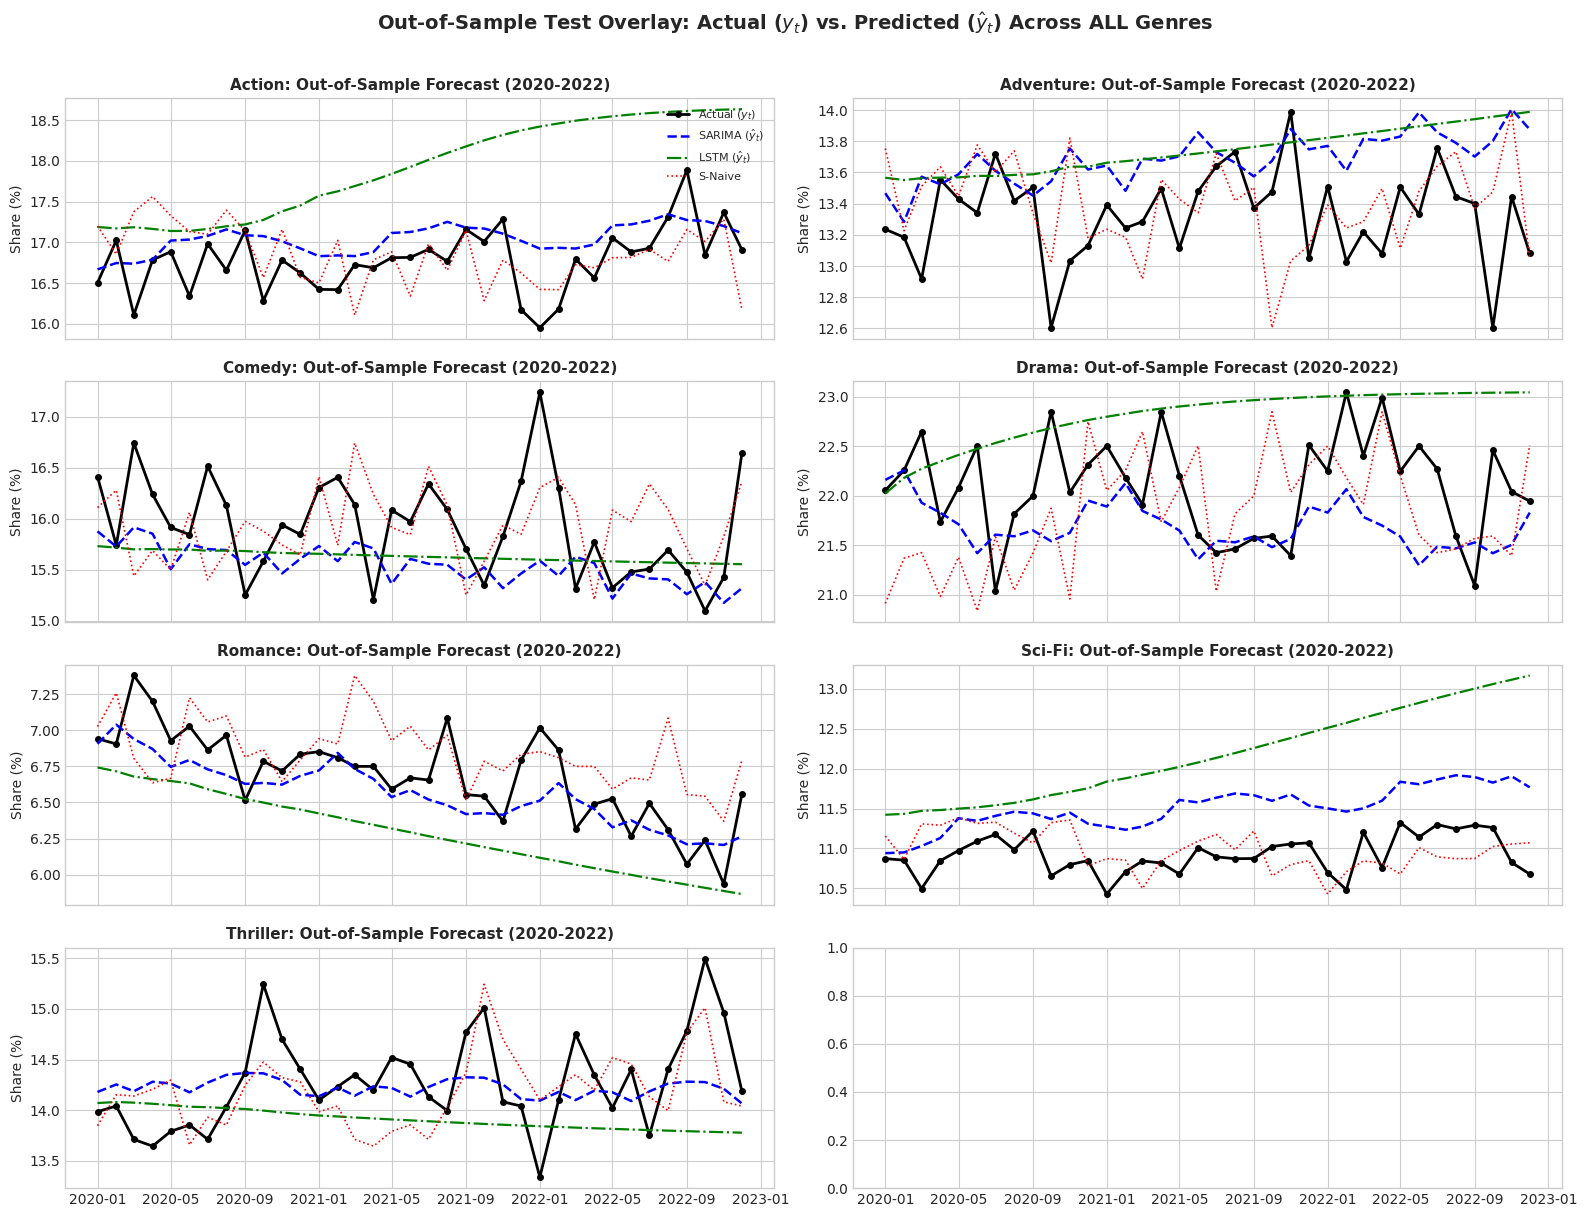

In [21]:
# ------------------------------------------------------------------------------
# STEP 5: VISUALIZATION OF OUR OUTPUT
# ------------------------------------------------------------------------------
# Generating all requested visual artifacts:
# 1. Residual Plots (time series, distribution KDE, and ACF)
# 2. (y, y') Time Series Overlay Plots for ALL genres
# 3. (y vs y') Scatter Fit Plots with 45° Reference Lines
# 4. Model Ranking Bar Chart
# ------------------------------------------------------------------------------
print("\n[Step 5] Generating Visual Output Dashboard...")

# ------------------------------------------------------------------------------
# 5A. (y, y') TIME SERIES OVERLAY PLOT (ALL GENRES)
# ------------------------------------------------------------------------------
n_g = len(target_genres)
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for i, g in enumerate(target_genres):
    y_actual = df_share.loc[test_idx, g]
    axes[i].plot(test_idx, y_actual, 'k-o', label='Actual ($y_t$)', lw=2.0, ms=4)
    axes[i].plot(test_idx, all_forecasts[g]['SARIMA'], 'b--', label='SARIMA ($\hat{y}_t$)', lw=1.8)
    axes[i].plot(test_idx, all_forecasts[g]['LSTM'], 'g-.', label='LSTM ($\hat{y}_t$)', lw=1.6)
    axes[i].plot(test_idx, all_forecasts[g]['Seasonal Naive'], 'r:', label='S-Naive', lw=1.2)
    
    axes[i].set_title(f"{g}: Out-of-Sample Forecast (2020-2022)", fontsize=11, fontweight='bold')
    axes[i].set_ylabel("Share (%)")
    if i == 0:
        axes[i].legend(loc='upper right', fontsize=8)

plt.suptitle("Out-of-Sample Test Overlay: Actual ($y_t$) vs. Predicted ($\hat{y}_t$) Across ALL Genres", 
             y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

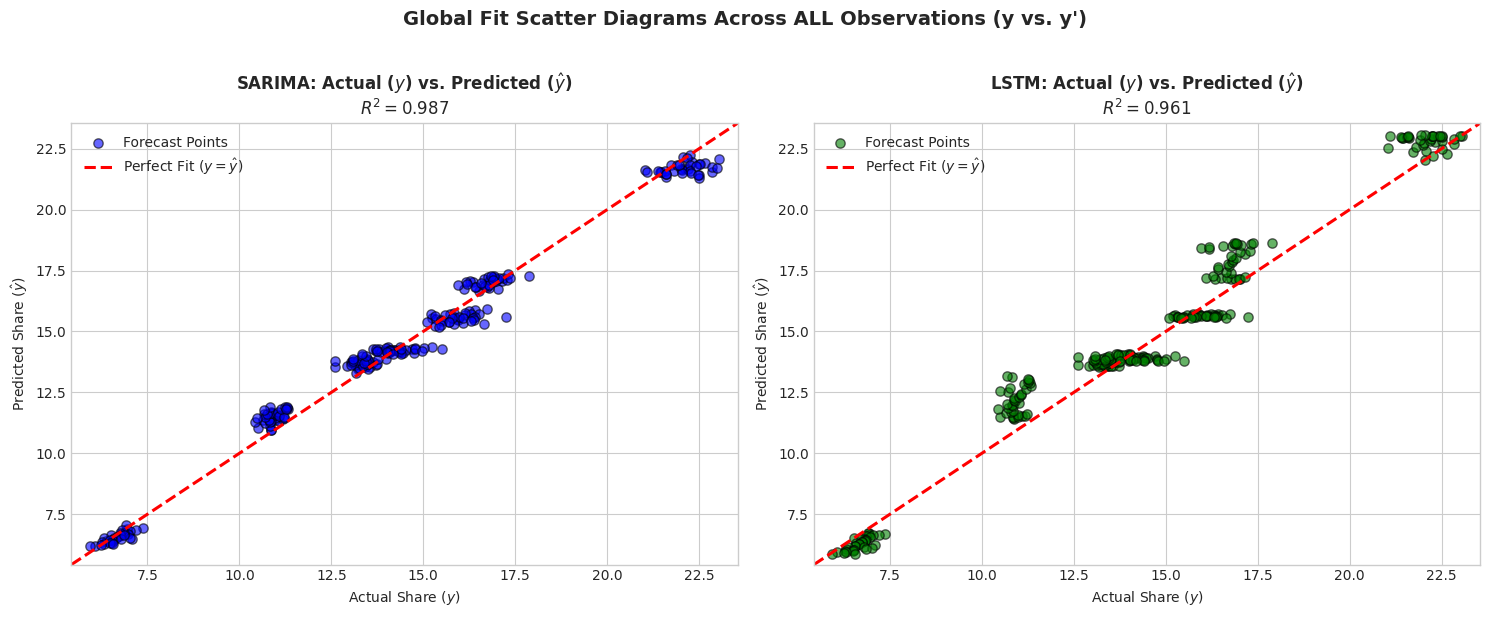

In [22]:
# ------------------------------------------------------------------------------
# 5B. (y vs y') SCATTER FIT PLOT WITH 45° REFERENCE LINE
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot SARIMA y vs y'
all_actual = np.concatenate([df_share.loc[test_idx, g].values for g in target_genres])
all_sarima = np.concatenate([all_forecasts[g]['SARIMA'] for g in target_genres])
all_lstm   = np.concatenate([all_forecasts[g]['LSTM'] for g in target_genres])

min_p = min(all_actual.min(), all_sarima.min()) - 0.5
max_p = max(all_actual.max(), all_sarima.max()) + 0.5

# Panel 1: SARIMA
axes[0].scatter(all_actual, all_sarima, color='blue', alpha=0.6, edgecolors='k', s=45, label='Forecast Points')
axes[0].plot([min_p, max_p], [min_p, max_p], 'r--', lw=2.2, label='Perfect Fit ($y = \hat{y}$)')
axes[0].set_title(f"SARIMA: Actual ($y$) vs. Predicted ($\hat{{y}}$)\n$R^2 = {r2_score(all_actual, all_sarima):.3f}$", fontsize=12)
axes[0].set_xlabel("Actual Share ($y$)")
axes[0].set_ylabel("Predicted Share ($\hat{y}$)")
axes[0].set_xlim(min_p, max_p); axes[0].set_ylim(min_p, max_p)
axes[0].legend()

# Panel 2: LSTM
axes[1].scatter(all_actual, all_lstm, color='green', alpha=0.6, edgecolors='k', s=45, label='Forecast Points')
axes[1].plot([min_p, max_p], [min_p, max_p], 'r--', lw=2.2, label='Perfect Fit ($y = \hat{y}$)')
axes[1].set_title(f"LSTM: Actual ($y$) vs. Predicted ($\hat{{y}}$)\n$R^2 = {r2_score(all_actual, all_lstm):.3f}$", fontsize=12)
axes[1].set_xlabel("Actual Share ($y$)")
axes[1].set_ylabel("Predicted Share ($\hat{y}$)")
axes[1].set_xlim(min_p, max_p); axes[1].set_ylim(min_p, max_p)
axes[1].legend()

plt.suptitle("Global Fit Scatter Diagrams Across ALL Observations (y vs. y')", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

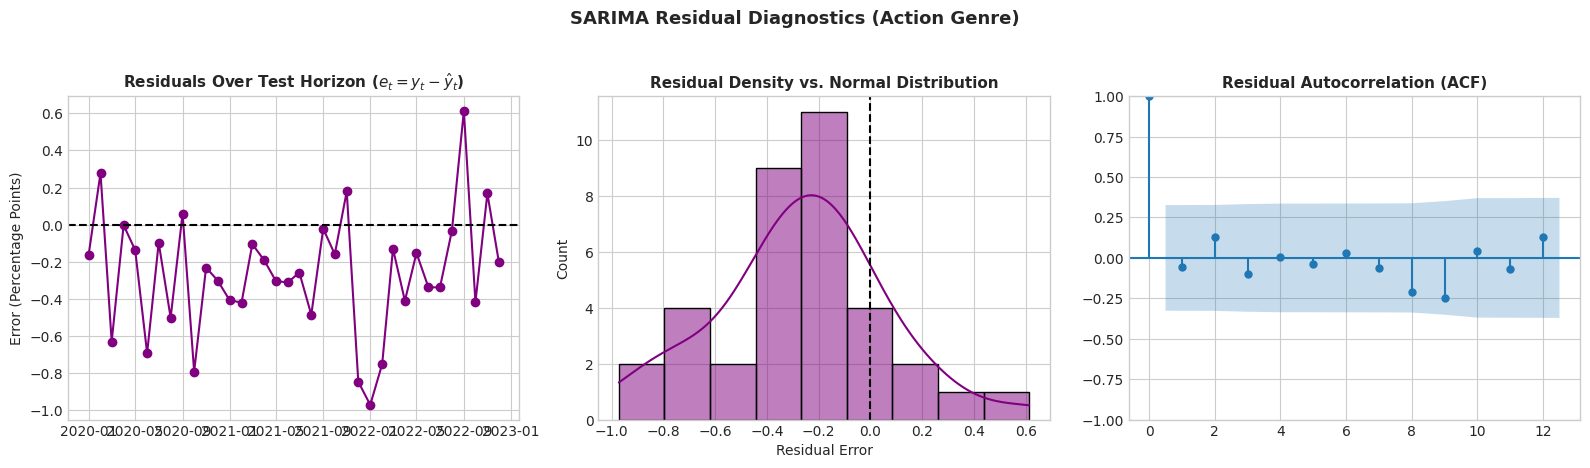

In [23]:
# ------------------------------------------------------------------------------
# 5C. RESIDUAL DIAGNOSTICS PLOTS (SARIMA on Action Genre)
# ------------------------------------------------------------------------------
action_actual = df_share.loc[test_idx, 'Action'].values
action_sarima = all_forecasts['Action']['SARIMA']
resids = action_actual - action_sarima

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Residuals vs Time
axes[0].plot(test_idx, resids, marker='o', color='purple', lw=1.5)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title("Residuals Over Test Horizon ($e_t = y_t - \hat{y}_t$)")
axes[0].set_ylabel("Error (Percentage Points)")

# Residual Histogram & KDE
sns.histplot(resids, kde=True, color='purple', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title("Residual Density vs. Normal Distribution")
axes[1].set_xlabel("Residual Error")

# ACF of Residuals
sm.graphics.tsa.plot_acf(resids, lags=12, ax=axes[2], title="Residual Autocorrelation (ACF)")

plt.suptitle("SARIMA Residual Diagnostics (Action Genre)", y=1.03, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

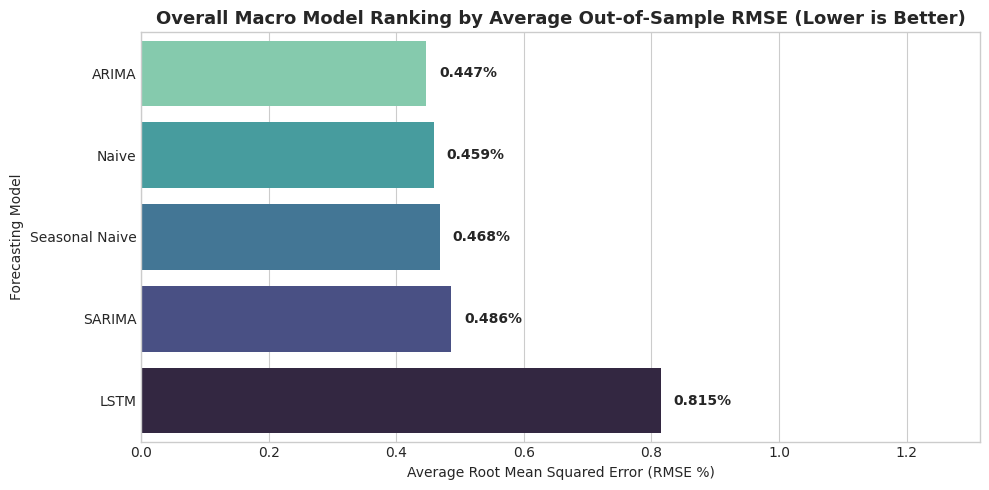

In [24]:
# ------------------------------------------------------------------------------
# 5D. MODEL RANKING BAR CHART
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))
df_macro_clean = macro_summary.copy()
df_macro_clean['RMSE_num'] = df_macro_clean['RMSE'].astype(float)

pal = sns.color_palette("mako_r", len(df_macro_clean))
barplot = sns.barplot(x="RMSE_num", y="Model", data=df_macro_clean, palette=pal)

for p in barplot.patches:
    val = p.get_width()
    barplot.annotate(f"{val:.3f}%", (val + 0.02, p.get_y() + p.get_height()/2.),
                     ha='left', va='center', fontsize=10, fontweight='bold')

plt.title("Overall Macro Model Ranking by Average Out-of-Sample RMSE (Lower is Better)", fontsize=13, fontweight='bold')
plt.xlabel("Average Root Mean Squared Error (RMSE %)")
plt.ylabel("Forecasting Model")
plt.xlim(0, df_macro_clean['RMSE_num'].max() + 0.5)
plt.tight_layout()
plt.show()

In [ ]:
# ------------------------------------------------------------------------------
# STEP 6: LJUNG-BOX STATISTICAL WHITENESS TEST
# ------------------------------------------------------------------------------
lb_test = sm.stats.acorr_ljungbox(resids, lags=[6, 12], return_df=True)
print("\nLjung-Box Formal Whiteness Test on SARIMA Residuals:")
print(lb_test)
if lb_test['lb_pvalue'].iloc[-1] > 0.05:
    print("-> Conclusion: Residuals show NO significant serial autocorrelation (White Noise verified).")


Ljung-Box Formal Whiteness Test on SARIMA Residuals:
     lb_stat  lb_pvalue
6   1.082732   0.982281
12  7.375562   0.831830
-> Conclusion: Residuals show NO significant serial autocorrelation (White Noise verified).
